# Mobility Data Exploration
### Create 09/20/2024
### Modified 11/20/2024

### Dr. Celis jcelis@ou.edu

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from glob import glob
import os
from tqdm import tqdm
import plotly.express as px
from skmob.core.trajectorydataframe import TrajDataFrame
from skmob.preprocessing import detection
from skmob.measures import individual

In [2]:
# Define the base directory containing the daily folders
base_dir = '/glade/u/home/jcelis/CAT/Data/Mobility/Veraset/2024/'

In [7]:
# Use glob to recursively find all .parquet files in the subdirectories
files = sorted(glob(os.path.join(base_dir, "*/*/*.parquet")))

In [8]:
# Count the number of files in the list
num_files = len(files)

# Print the count
print(f"Total number of files: {num_files}")

Total number of files: 12288


In [9]:
data_list = []
for data_file in tqdm(files):
    data_list.append(pd.read_parquet(data_file)[['utc_timestamp', 'caid', 'id_type', 'latitude', 'longitude']])
data = pd.concat(data_list)

100%|██████████| 12288/12288 [2:24:15<00:00,  1.42it/s] 


In [10]:
data.reset_index(inplace=True)

In [ ]:
tdf = TrajDataFrame(data, 
                    latitude="latitude", 
                    longitude="longitude",
                    datetime="utc_timestamp",
                    user_id="caid")

In [19]:
tdf_sorted = tdf.sort_values(by=["uid", "datetime"])

In [20]:
tdf_sorted

,level_0,index,datetime,uid,id_type,lat,lng
28411904,28411904,74012,2024-03-21 02:42:20,0000059f360d204cde22d2768c39cfa1c8667aaa58ba22...,idfa,41.84664,-124.13385
28401081,28401081,63189,2024-03-21 02:42:25,0000059f360d204cde22d2768c39cfa1c8667aaa58ba22...,idfa,41.84660,-124.13385
28428505,28428505,90613,2024-03-21 02:45:18,0000059f360d204cde22d2768c39cfa1c8667aaa58ba22...,idfa,41.84664,-124.13386
28338652,28338652,760,2024-03-21 03:05:09,0000059f360d204cde22d2768c39cfa1c8667aaa58ba22...,idfa,41.84662,-124.13385
28384447,28384447,46555,2024-03-21 05:21:44,0000059f360d204cde22d2768c39cfa1c8667aaa58ba22...,idfa,41.84670,-124.13391
...,...,...,...,...,...,...,...
19424256,19424256,54677,2024-03-21 08:32:41,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65536,-117.66120
19394109,19394109,24530,2024-03-21 08:32:44,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65529,-117.66127
19373790,19373790,4211,2024-03-21 08:32:48,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65529,-117.66121
19467516,19467516,97937,2024-03-21 08:32:49,fffffe6bc17118860ef11d5bf59a725c69b640a91dd276...,idfa,33.65535,-117.66128


In [1]:
tdf

NameError: name 'tdf' is not defined

In [21]:
users = pd.unique(tdf_sorted["uid"])

In [22]:
user_counts = tdf_sorted.groupby("uid")["uid"].count()

In [23]:
user_counts[user_counts > 5000]

uid
5adf01460023b8115154e45efce6ad98fd16e2f6370f71d71aee2e6a0900148c    5550
6d3a7a719adc4fab8325a3acc242eeae78ae7e5459bd66df0da47b94f635f1e1    5501
7b78cd14e11b4916446472b25a4b084e6988a5d901786e083653c4b672bba70a    5396
81accda2c6162c94a049031e96a645dfa3e6a1a1d62bd610a9926a79a3756718    7409
89c7edbdd80a5779aa9ceb3673a817c17260966aa0e367ab9c8cb26d553443e5    5210
d6985241d09fb54540391091da88fd4650688992df33c19c1826714650111802    7025
ee9dc840f3cd8ff46ca65515b59dc51e493e6756c80e9129c6589790e8b0248d    5296
Name: uid, dtype: int64

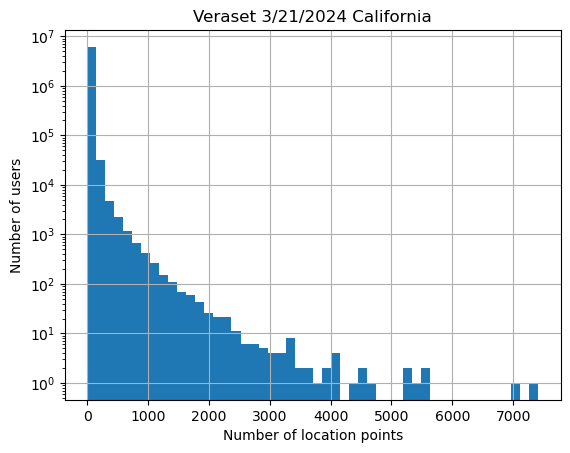

In [25]:
user_counts.hist(bins=50)
plt.gca().set_yscale("log")
plt.xlabel("Number of location points")
plt.ylabel("Number of users")
plt.title("Veraset 3/21/2024 California")
plt.savefig("veraset_user_counts.png", dpi=300, bbox_inches="tight")

In [40]:
#tdf_u = tdf_sorted[tdf_sorted["uid"] == 'd6985241d09fb54540391091da88fd4650688992df33c19c1826714650111802']
tdf_u = tdf_sorted[tdf_sorted["uid"] == '5adf01460023b8115154e45efce6ad98fd16e2f6370f71d71aee2e6a0900148c']

In [50]:
tdf_u

,level_0,index,datetime,uid,id_type,lat,lng
55928273,55928273,24470,2024-03-21 00:00:10,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729457,-117.194518
55910303,55910303,6500,2024-03-21 00:00:12,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729479,-117.194629
55995358,55995358,91555,2024-03-21 00:00:23,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729502,-117.195711
55910409,55910409,6606,2024-03-21 00:00:30,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729497,-117.196664
55936912,55936912,33109,2024-03-21 00:00:36,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729524,-117.197492
...,...,...,...,...,...,...,...
55947303,55947303,43500,2024-03-21 23:59:30,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.050264,-117.073185
55921398,55921398,17595,2024-03-21 23:59:35,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.048857,-117.073173
55947361,55947361,43558,2024-03-21 23:59:44,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.046392,-117.073104
55941606,55941606,37803,2024-03-21 23:59:48,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.045335,-117.073250


In [51]:
nlocs = individual.number_of_locations(tdf_sorted)

  0%|          | 0/6156408 [00:16<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
nlocs["number_of_locations"].argmax()

In [42]:
stays = detection.stay_locations(tdf_u, )

In [43]:
stays

,level_0,index,datetime,uid,id_type,lat,lng,leaving_datetime
0,55978345,74542,2024-03-21 01:50:21,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.273162,-117.287835,2024-03-21 03:16:55
1,55910381,6578,2024-03-21 06:15:32,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.562503,-117.083551,2024-03-21 14:27:14
2,55914493,10690,2024-03-21 15:53:08,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.995403,-117.254504,2024-03-21 16:19:14


In [44]:
map_f = tdf_u.plot_trajectory(max_points=None)
stays.plot_stops(map_f=map_f)

/glade/work/jcelis/conda-envs/pycat/lib/python3.11/site-packages/skmob/core/trajectorydataframe.py:569: UserWarning: Only the trajectories of the first 10 users will be plotted. Use the argument `max_users` to specify the desired number of users, or filter the TrajDataFrame.
  return plot.plot_trajectory(self, map_f=map_f, max_users=max_users, max_points=max_points, style_function=style_function,
/glade/work/jcelis/conda-envs/pycat/lib/python3.11/site-packages/skmob/core/trajectorydataframe.py:646: UserWarning: Only the stops of the first 10 users will be plotted. Use the argument `max_users` to specify the desired number of users, or filter the TrajDataFrame.
  return plot.plot_stops(self, map_f=map_f, max_users=max_users, tiles=tiles, zoom=zoom,


In [38]:
import folium
import pandas as pd

# Assuming df is the name of your DataFrame
df=data
# Filter the DataFrame for the specific caid
caid_specific_df = df[df['caid'] == '5adf01460023b8115154e45efce6ad98fd16e2f6370f71d71aee2e6a0900148c']
#caid_specific_df = df[df['caid'] == 'd6985241d09fb54540391091da88fd4650688992df33c19c1826714650111802']
 
# Clean the latitude and longitude columns
# Ensure that latitude and longitude contain valid numeric values
caid_specific_df['latitude'] = pd.to_numeric(caid_specific_df['latitude'], errors='coerce')
caid_specific_df['longitude'] = pd.to_numeric(caid_specific_df['longitude'], errors='coerce')

# Drop rows where latitude or longitude couldn't be converted to numeric (NaN)
caid_specific_df = caid_specific_df.dropna(subset=['latitude', 'longitude'])

# Sort the data by timestamp to get the movement in correct order
caid_specific_df = caid_specific_df.sort_values(by='utc_timestamp')

# Initialize the map centered around the average of the lat/lon
avg_lat = caid_specific_df['latitude'].mean()
avg_lon = caid_specific_df['longitude'].mean()
m = folium.Map(location=[avg_lat, avg_lon], zoom_start=12)

# Get the first and last row for different colors
start_point = caid_specific_df.iloc[0]
end_point = caid_specific_df.iloc[-1]

# Plot all points in between with the same color
for i, row in caid_specific_df.iterrows():
    folium.CircleMarker(
        location=[row['latitude'], row['longitude']],
        radius=5,
        color='blue',
        fill=True,
        fill_color='blue',
        popup=f"Timestamp: {row['utc_timestamp']}",
    ).add_to(m)

# Highlight the start point
folium.Marker(
    location=[start_point['latitude'], start_point['longitude']],
    popup=f"Start: {start_point['utc_timestamp']}",
    icon=folium.Icon(color='green')
).add_to(m)

# Highlight the end point
folium.Marker(
    location=[end_point['latitude'], end_point['longitude']],
    popup=f"End: {end_point['utc_timestamp']}",
    icon=folium.Icon(color='red')
).add_to(m)

# Optionally, connect the points with lines
locations = caid_specific_df[['latitude', 'longitude']].values.tolist()
folium.PolyLine(locations, color='blue').add_to(m)

# Display the map
m

/glade/derecho/scratch/jcelis/tmp/ipykernel_10076/519470633.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  caid_specific_df['latitude'] = pd.to_numeric(caid_specific_df['latitude'], errors='coerce')
/glade/derecho/scratch/jcelis/tmp/ipykernel_10076/519470633.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  caid_specific_df['longitude'] = pd.to_numeric(caid_specific_df['longitude'], errors='coerce')


In [45]:
one_person = data[data["caid"] == '5adf01460023b8115154e45efce6ad98fd16e2f6370f71d71aee2e6a0900148c']

In [1]:
plt.scatter(one_person["longitude"].values, 
            one_person["latitude"].values, 10, one_person["time"])

NameError: name 'plt' is not defined

In [47]:
one_person

,level_0,index,utc_timestamp,caid,id_type,latitude,longitude
55904989,55904989,1186,2024-03-21 00:11:53,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729046,-117.209762
55904990,55904990,1187,2024-03-21 17:14:10,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.729608,-117.195977
55904991,55904991,1188,2024-03-21 14:49:24,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.651365,-117.150615
55904992,55904992,1189,2024-03-21 17:02:27,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.71994,-117.169246
55904993,55904993,1190,2024-03-21 00:30:28,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.757691,-117.203877
...,...,...,...,...,...,...,...
56004267,56004267,100464,2024-03-21 15:25:02,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.779476,-117.162817
56004268,56004268,100465,2024-03-21 19:12:48,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,32.843399,-117.27839
56004269,56004269,100466,2024-03-21 01:26:56,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.202224,-117.377105
56004270,56004270,100467,2024-03-21 03:30:19,5adf01460023b8115154e45efce6ad98fd16e2f6370f71...,idfa,33.212504,-117.367303


In [53]:
import geopandas as gpd

In [54]:
counties = gpd.read_file("https://raw.githubusercontent.com/codeforgermany/click_that_hood/master/public/data/california-counties.geojson")

In [55]:
# Reproject data to NAD83(HARN) / California Zone 3 (EPSG: 4326)
# https://spatialreference.org/ref/epsg/2768/
proj = 4326
counties = counties.to_crs(epsg=proj)

In [56]:
 print(counties.head())

        name  cartodb_id                created_at                updated_at  \
0    Alameda           1 2015-07-04 21:04:58+00:00 2015-07-04 21:04:58+00:00   
1     Alpine           2 2015-07-04 21:04:58+00:00 2015-07-04 21:04:58+00:00   
2     Amador           3 2015-07-04 21:04:58+00:00 2015-07-04 21:04:58+00:00   
3      Butte           4 2015-07-04 21:04:58+00:00 2015-07-04 21:04:58+00:00   
4  Calaveras           5 2015-07-04 21:04:58+00:00 2015-07-04 21:04:58+00:00   

                                            geometry  
0  MULTIPOLYGON (((-122.31293 37.89733, -122.2884...  
1  POLYGON ((-120.07239 38.70277, -119.96495 38.7...  
2  POLYGON ((-121.02726 38.48925, -121.02741 38.5...  
3  POLYGON ((-121.87925 39.30361, -121.90831 39.3...  
4  POLYGON ((-120.87605 38.02889, -120.91875 38.0...  


## Flow data frame

In [ ]:
# load real flows into a FlowDataFrame
fdf = skmob.FlowDataFrame.from_file(skmob.utils.constants.NY_FLOWS_2011,
				tessellation=tessellation,
				tile_id='tile_ID',
				sep=",")
>>> # print a portion of the flows
>>> print(fdf.head())

In [57]:
# Load California ZIP codes GeoJSON
zip_codes = gpd.read_file("https://raw.githubusercontent.com/OpenDataDE/State-zip-code-GeoJSON/master/ca_california_zip_codes_geo.min.json")

# Display the first few rows of the GeoDataFrame
print(zip_codes.head())

  STATEFP10 ZCTA5CE10  GEOID10 CLASSFP10 MTFCC10 FUNCSTAT10   ALAND10  \
0        06     94601  0694601        B5   G6350          S   8410939   
1        06     94501  0694501        B5   G6350          S  20539466   
2        06     94560  0694560        B5   G6350          S  35757865   
3        06     94587  0694587        B5   G6350          S  51075108   
4        06     94580  0694580        B5   G6350          S   8929836   

   AWATER10   INTPTLAT10    INTPTLON10 PARTFLG10  \
0    310703  +37.7755447  -122.2187049         N   
1   9005303  +37.7737968  -122.2781230         N   
2     60530  +37.5041413  -122.0323587         N   
3         0  +37.6031556  -122.0186382         N   
4     17052  +37.6757312  -122.1330170         N   

                                            geometry  
0  POLYGON ((-122.22717 37.79197, -122.22693 37.7...  
1  POLYGON ((-122.29181 37.76301, -122.30661 37.7...  
2  POLYGON ((-122.05499 37.5496, -122.05441 37.55...  
3  POLYGON ((-122.06515 37.6